# EAGLE · 02 — Explorar y enriquecer la base territorial

Este notebook **no genera ninguna cuadrícula**, no necesita PyPSA-Eur y nunca modifica `data/base/eagle_territorio.gpkg`.

**Funciones:** cargar el GeoPackage compartido, revisar territorios, dibujar mapas, filtrar por país o región, añadir variables desde CSV utilizando `celda_id`, visualizar sus valores y exportar un conjunto de datos enriquecido a `data/processed/`.

> **Instalación (solo si faltan paquetes):** ejecuta en una celda `%pip install geopandas shapely pyproj pyogrio requests matplotlib numpy pandas` y reinicia el kernel.
> Requiere conexión a Internet **solo la primera vez** para obtener los límites territoriales; se guardan en `data/fuentes_geograficas/`. Los cálculos posteriores funcionan sin Internet cuando ya existen los archivos descargados.


## 1 Configurar ruta de la base y cargarla

In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# MODIFICA SOLO SI CAMBIAS LA UBICACIÓN DEL ARCHIVO COMPARTIDO
RUTA_BASE = Path('data/base/eagle_territorio.gpkg')
RUTA_PROCESADOS = Path('data/processed')
RUTA_VARIABLES = Path('data/variables')
RUTA_PROCESADOS.mkdir(parents=True, exist_ok=True)
RUTA_VARIABLES.mkdir(parents=True, exist_ok=True)

if not RUTA_BASE.exists():
    raise FileNotFoundError(
        f'No existe {RUTA_BASE.resolve()}. Copia aquí el GeoPackage que generó el notebook 01.'
    )

base = gpd.read_file(RUTA_BASE, layer='celdas')

territorios = gpd.read_file(
    RUTA_BASE,
    layer="limites_territoriales"
)

print("Celdas:", len(base))
print("Territorios:", len(territorios))

assert base['celda_id'].is_unique
print(f'Base cargada: {len(base):,} celdas. CRS: {base.crs}')
display(base.head())

Celdas: 6356
Territorios: 8
Base cargada: 6,356 celdas. CRS: EPSG:3035


,celda_id,pais,territorio,latitud,longitud,superficie_tierra_km2,porcentaje_tierra,geometry
0,E.001.025,España,Canarias,27.739800,-15.600963,0.884545,0.884545,"POLYGON ((1790000 940000, 1790000 950000, 1780..."
1,E.001.026,España,Canarias,27.744500,-15.582680,4.799401,4.799401,"POLYGON ((1800000 940000, 1800000 950000, 1790..."
2,E.001.037,España,Canarias,28.076278,-14.444625,7.422027,7.422027,"POLYGON ((1910000 940000, 1910000 950000, 1900..."
3,E.001.038,España,Canarias,28.073885,-14.373911,60.599222,60.599222,"POLYGON ((1920000 940000, 1920000 950000, 1910..."
4,E.001.039,España,Canarias,28.094737,-14.300302,48.387500,48.387500,"POLYGON ((1930000 940000, 1930000 950000, 1920..."


In [2]:
# Cartografía de países de Natural Earth
url = (
    "https://naturalearth.s3.amazonaws.com/"
    "10m_cultural/ne_10m_admin_0_countries.zip"
)

territorios = gpd.read_file(url)

# Seleccionar España, Portugal y Andorra
territorios = territorios[
    territorios["ADMIN"].isin([
        "Spain", "Portugal", "Andorra"
    ])
].copy()

# Mismo sistema de coordenadas que nuestra base
territorios = territorios.to_crs(base.crs)

print("Territorios cargados:", len(territorios))

Territorios cargados: 3


## 2 · Inventario de regiones y calidad de la malla

In [3]:
resumen = (base.groupby(['pais','territorio'], dropna=False)
           .agg(celdas=('celda_id','size'),
                superficie_terrestre_km2=('superficie_tierra_km2','sum'))
           .reset_index()
           .sort_values(['pais','territorio']))
display(resumen)
print('Celdas costeras/parciales:', (base['porcentaje_tierra'] < 99.999).sum())
print('IDs repetidos:', base.celda_id.duplicated().sum())

,pais,territorio,celdas,superficie_terrestre_km2
0,Andorra,Andorra,7,406.469308
1,España,Baleares,95,4990.894664
2,España,Canarias,153,7450.460913
3,España,Ceuta,2,20.340482
4,España,España peninsular,5147,493369.069944
5,España,Melilla,6,14.130329
6,Gibraltar,Gibraltar,1,1.358807
7,Portugal,Portugal continental,945,89340.480972


Celdas costeras/parciales: 857
IDs repetidos: 0


## 3 Mapa de celdas (vista peninsular y archipiélagos por separado)

Para que Canarias pueda verse a escala legible, se genera una figura distinta. Cambia `TERRITORIOS_MAPA` para mostrar otras regiones.

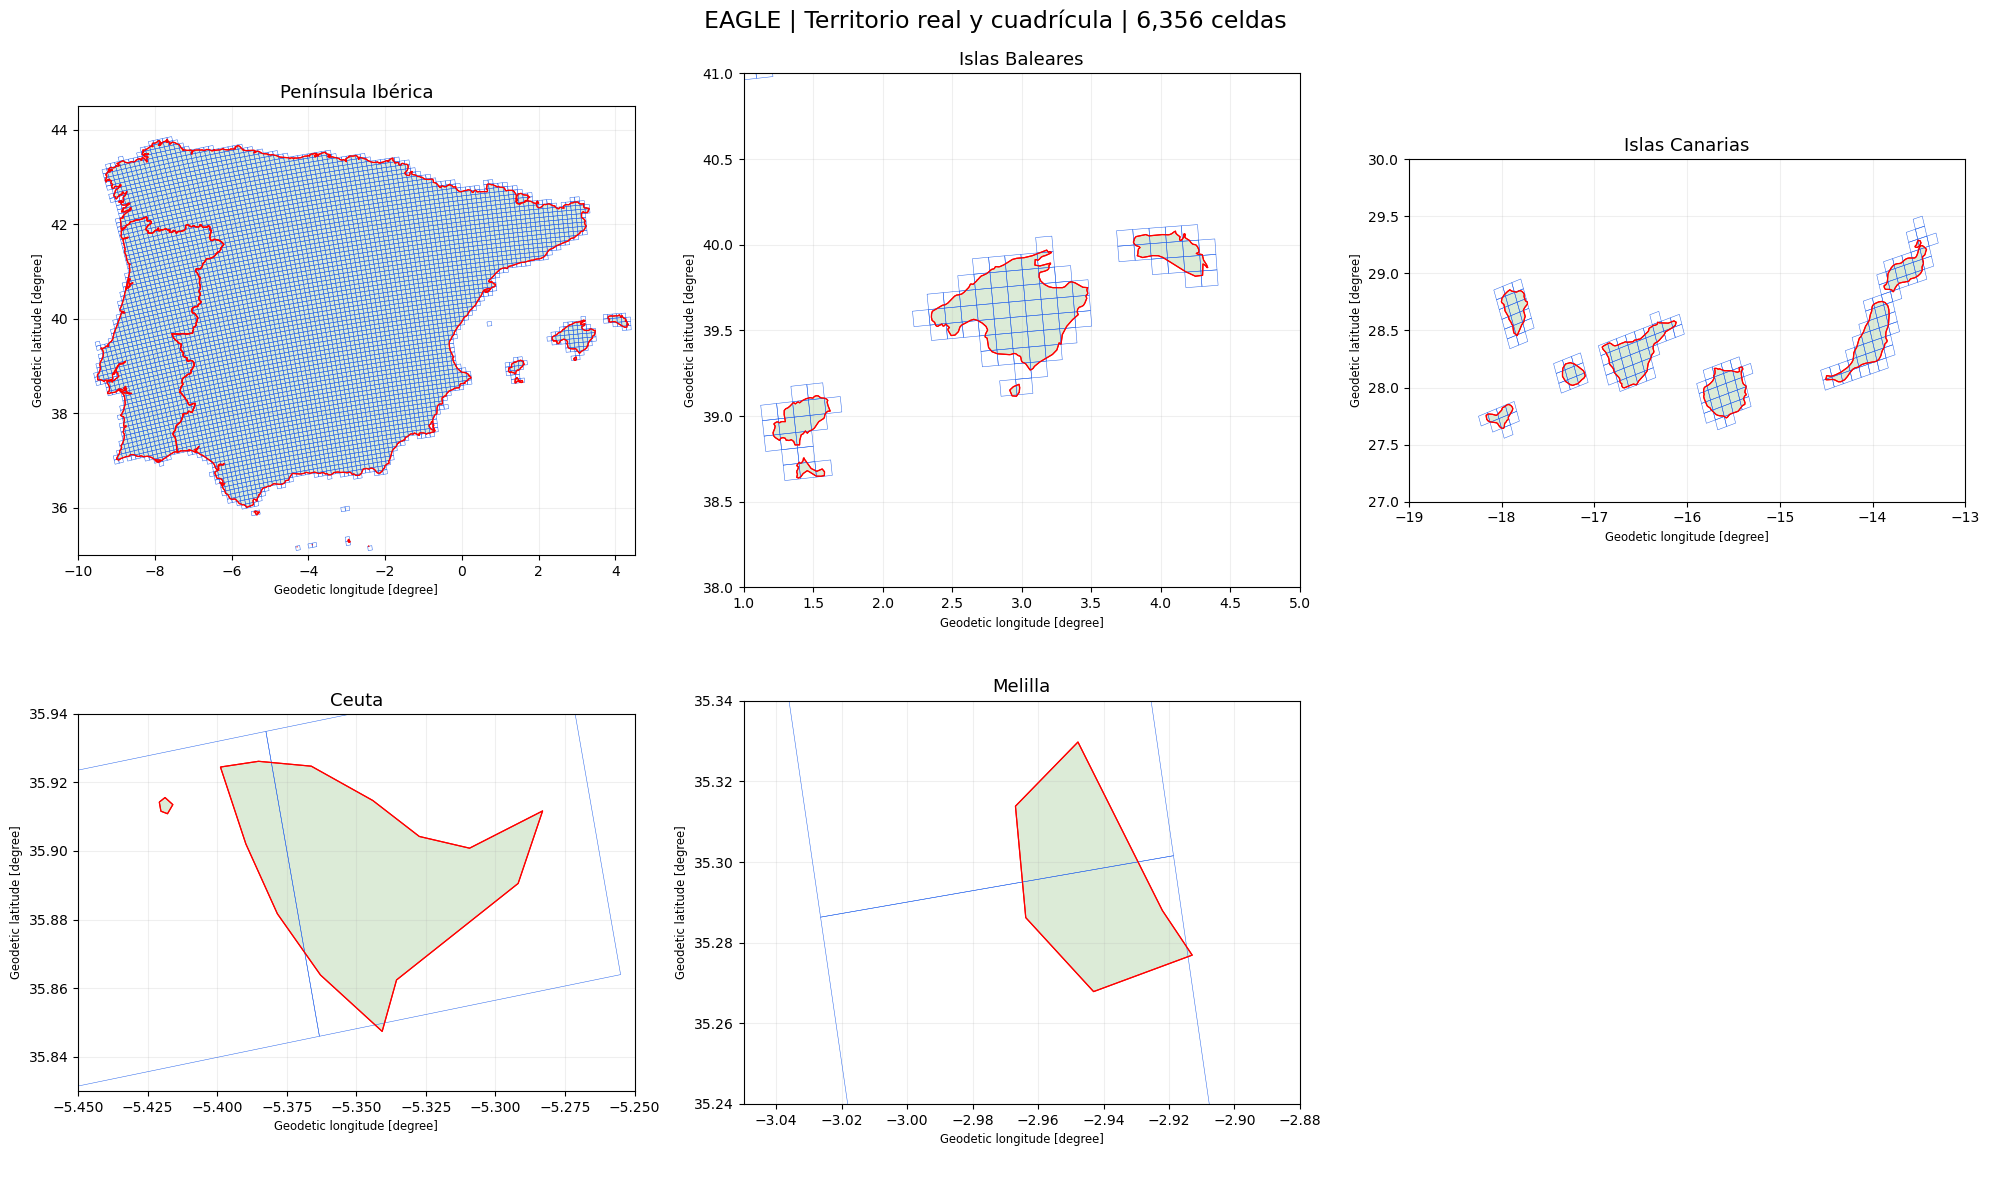

In [4]:
# Convertir a coordenadas geográficas
base_geo = base.to_crs("EPSG:4326")
territorios_geo = territorios.to_crs("EPSG:4326")

regiones = {
    "Península Ibérica": (-10, 4.5, 35, 44.5),
    "Islas Baleares": (1, 5, 38, 41),
    "Islas Canarias": (-19, -13, 27, 30),
    "Ceuta": (-5.45, -5.25, 35.83, 35.94),
    "Melilla": (-3.05, -2.88, 35.24, 35.34)
}

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, (nombre, limites) in zip(axes, regiones.items()):

    xmin, xmax, ymin, ymax = limites

    # Selección espacial
    territorio_region = territorios_geo.cx[xmin:xmax, ymin:ymax]
    celdas_region = base_geo.cx[xmin:xmax, ymin:ymax]

    # Territorio real (fondo)
    territorio_region.plot(
        ax=ax,
        facecolor="#dcebd7",
        edgecolor="red",
        linewidth=0.8,
        zorder=1
    )

    # Cuadrículas transparentes
    celdas_region.boundary.plot(
        ax=ax,
        color="#2563eb",
        linewidth=0.35,
        zorder=2
    )

    # Contorno terrestre por encima de la cuadrícula
    territorio_region.boundary.plot(
        ax=ax,
        color="red",
        linewidth=0.9,
        zorder=3
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.set_title(nombre, fontsize=13)
    ax.grid(alpha=0.2)

for ax in axes[len(regiones):]:
    ax.axis("off")

fig.suptitle(
    f"EAGLE | Territorio real y cuadrícula "
    f"| {len(base):,} celdas",
    fontsize=17
)

plt.tight_layout()
plt.show()

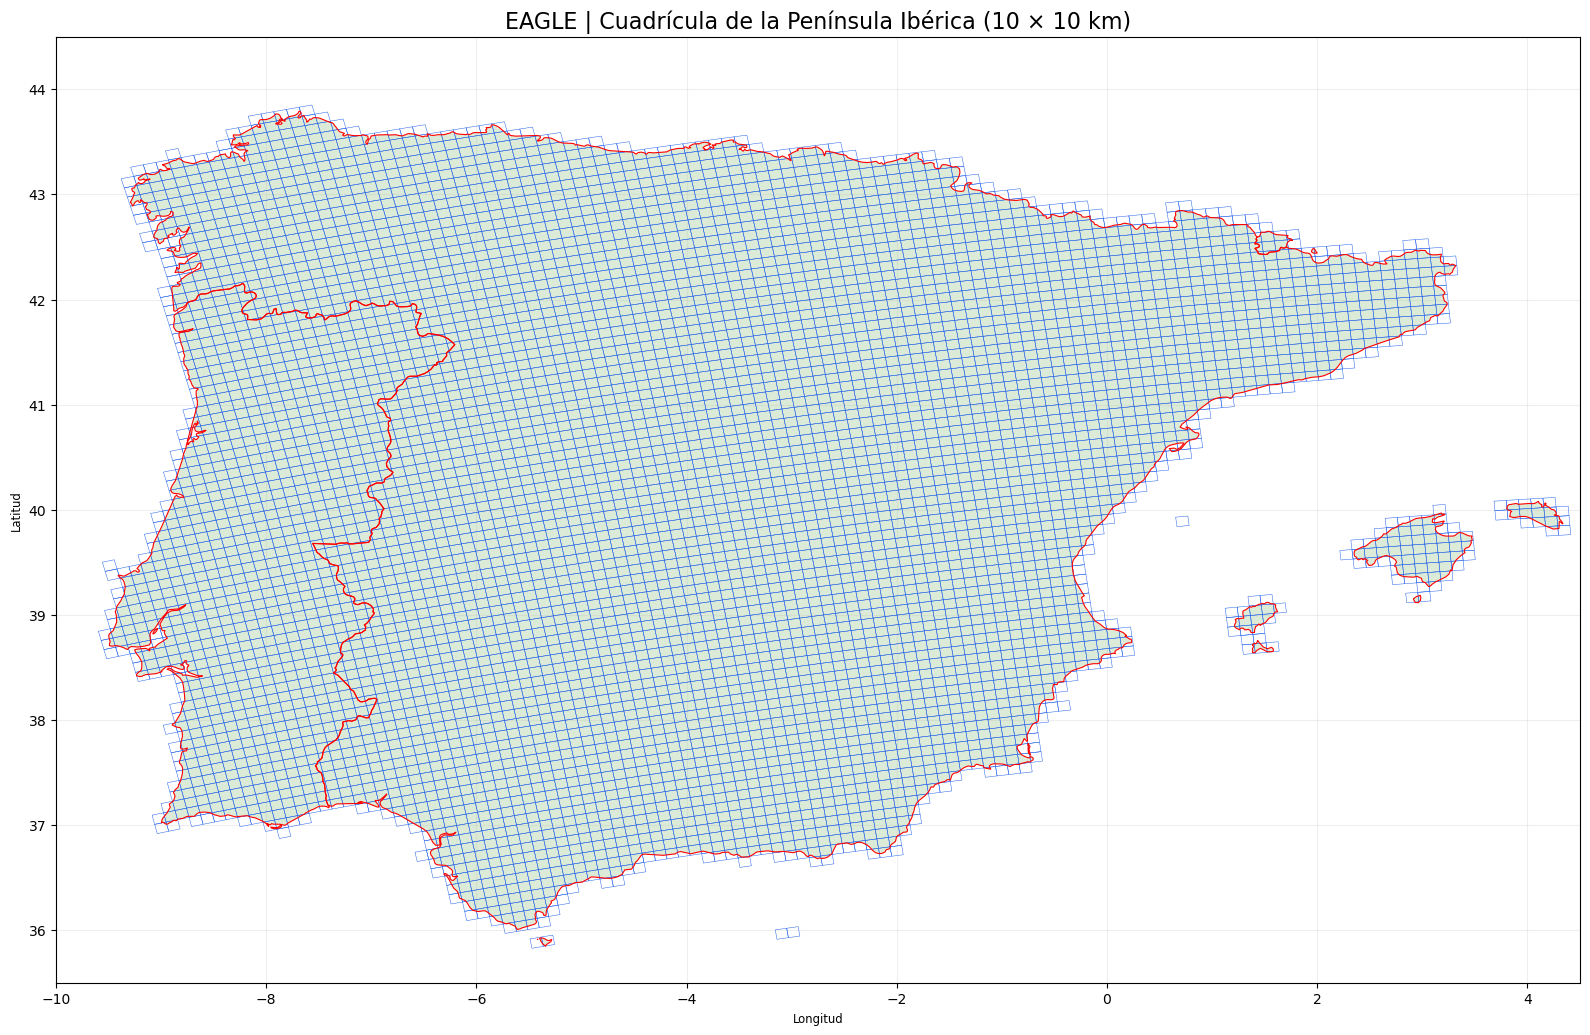

In [5]:
# Convertir a coordenadas geográficas
base_geo = base.to_crs("EPSG:4326")
territorios_geo = territorios.to_crs("EPSG:4326")

# Límites de la Península Ibérica
xmin, xmax = -10, 4.5
ymin, ymax = 35.5, 44.5

# Seleccionar la zona
celdas_peninsula = base_geo.cx[xmin:xmax, ymin:ymax]
territorio_peninsula = territorios_geo.cx[xmin:xmax, ymin:ymax]

# Crear mapa
fig, ax = plt.subplots(figsize=(16, 12))

# Superficie terrestre real
territorio_peninsula.plot(
    ax=ax,
    facecolor="#dcebd7",
    edgecolor="none",
    zorder=1
)

# Cuadrícula de 10 x 10 km
celdas_peninsula.boundary.plot(
    ax=ax,
    color="#2563eb",
    linewidth=0.35,
    zorder=2
)

# Límites reales del territorio
territorio_peninsula.boundary.plot(
    ax=ax,
    color="red",
    linewidth=0.8,
    zorder=3
)

# Ajustes
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_title(
    f"EAGLE | Cuadrícula de la Península Ibérica "
    f"({TAMANO_CELDA_KM if 'TAMANO_CELDA_KM' in globals() else 10} × "
    f"{TAMANO_CELDA_KM if 'TAMANO_CELDA_KM' in globals() else 10} km)",
    fontsize=16
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 4 Filtrar celdas y consultar atributos

In [6]:
# Mostrar tabla sin la geometría (para facilitar la lectura)
display(base.drop(columns="geometry"))

,celda_id,pais,territorio,latitud,longitud,superficie_tierra_km2,porcentaje_tierra
0,E.001.025,España,Canarias,27.739800,-15.600963,0.884545,0.884545
1,E.001.026,España,Canarias,27.744500,-15.582680,4.799401,4.799401
2,E.001.037,España,Canarias,28.076278,-14.444625,7.422027,7.422027
3,E.001.038,España,Canarias,28.073885,-14.373911,60.599222,60.599222
4,E.001.039,España,Canarias,28.094737,-14.300302,48.387500,48.387500
...,...,...,...,...,...,...,...
6351,E.153.134,España,España peninsular,43.693295,-8.047938,12.999742,12.999742
6352,E.153.135,España,España peninsular,43.717938,-7.948748,38.409567,38.409567
6353,E.153.136,España,España peninsular,43.737657,-7.888616,29.835702,29.835702
6354,E.153.137,España,España peninsular,43.763903,-7.696683,22.973591,22.973591
